SyntaxError: invalid non-printable character U+00A0 (442493397.py, line 19)

SyntaxError: invalid non-printable character U+00A0 (3595147762.py, line 13)


Dataset Shape: (569, 31)

First 5 Rows:
   diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0          1        17.99         10.38          122.80     1001.0   
1          1        20.57         17.77          132.90     1326.0   
2          1        19.69         21.25          130.00     1203.0   
3          1        11.42         20.38           77.58      386.1   
4          1        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  ...  radius_worst  texture_worst  perimeter_worst  \
0   

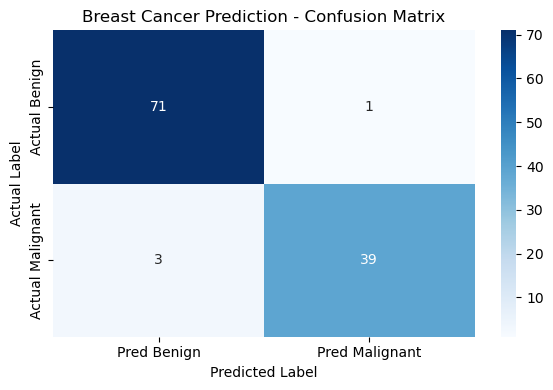


Top 5 Features Pushing Towards MALIGNANT:
                feature  coefficient
21        texture_worst     1.429023
10            radius_se     1.237079
28       symmetry_worst     1.062661
7   concave points_mean     0.948610
13              area_se     0.913437

Top 5 Features Pushing Towards BENIGN:
                 feature  coefficient
18           symmetry_se    -0.332383
11            texture_se    -0.408740
5       compactness_mean    -0.441220
19  fractal_dimension_se    -0.591392
15        compactness_se    -0.907620

Threshold   Precision   Recall   F1-score
0.1         0.891       0.976    0.932
0.3         0.976       0.976    0.976
0.5         0.975       0.929    0.951
0.7         1.000       0.905    0.950
0.9         1.000       0.786    0.880

Project Execution Completed Successfully!


In [4]:
# ---------------------------------------------------------------
# 0. IMPORT LIBRARIES
# ---------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ---------------------------------------------------------------
# 1. UPLOAD AND LOAD DATASET
# ---------------------------------------------------------------



df = pd.read_csv(r"C:\Users\user\Downloads\archive (23)\data.csv")

df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("\nDataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nClass Balance:")
print(df["diagnosis"].value_counts())

print("\nMissing Values:", df.isnull().sum().sum())

# ---------------------------------------------------------------
# 2. FEATURES, TARGET AND TRAIN-TEST SPLIT
# ---------------------------------------------------------------

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ---------------------------------------------------------------
# 3. BUILD AND TRAIN LOGISTIC REGRESSION MODEL
# ---------------------------------------------------------------

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# ---------------------------------------------------------------
# 4. PREDICTION
# ---------------------------------------------------------------

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# ---------------------------------------------------------------
# 5. MODEL EVALUATION
# ---------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix:\n", cm)

print(f"\nTN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print("\nAccuracy  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC   :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

# ---------------------------------------------------------------
# 6. CONFUSION MATRIX VISUALIZATION
# ---------------------------------------------------------------

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)

plt.title("Breast Cancer Prediction - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# ---------------------------------------------------------------
# 7. FEATURE IMPORTANCE / COEFFICIENT ANALYSIS
# ---------------------------------------------------------------

coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
})

coef_df = coef_df.sort_values(
    "coefficient",
    ascending=False
)

print("\nTop 5 Features Pushing Towards MALIGNANT:")
print(coef_df.head(5))

print("\nTop 5 Features Pushing Towards BENIGN:")
print(coef_df.tail(5))

# ---------------------------------------------------------------
# 8. THRESHOLD EXPERIMENT
# ---------------------------------------------------------------

print("\nThreshold   Precision   Recall   F1-score")

for t in [0.1, 0.3, 0.5, 0.7, 0.9]:

    pred_t = (y_prob >= t).astype(int)

    precision = precision_score(
        y_test, pred_t, zero_division=0
    )

    recall = recall_score(y_test, pred_t)

    f1 = f1_score(y_test, pred_t, zero_division=0)

    print(
        f"{t:.1f}         {precision:.3f}       "
        f"{recall:.3f}    {f1:.3f}"
    )

# ---------------------------------------------------------------
# 9. DOWNLOAD CONFUSION MATRIX
# ---------------------------------------------------------------

print("\nProject Execution Completed Successfully!")

